<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~④ 는 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b>.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300"><br><br><small>④ 사이트로 돌아와 <b>『📓 내 Colab 실습 노트』</b> 칸에 붙여넣고 <b>『보관』</b>을 눌러요 — <b>『✅ 보관됨』</b>이 뜨면 선생님께 간 거예요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_paste.jpg" width="300">

<small>☁ <b>저장 확인</b> — 맨 위 노트 이름 옆에 <b>체크된 구름</b>이 보이면 내 드라이브에 <b>실시간으로 저장</b>되고 있어요. (구름이 없고 「Drive로 복사」가 보이면 아직 내 노트가 아니에요 — 파일 → Drive에 사본 저장)</small><br>

![체크된 구름 = 저장 잘 되는 중](https://raw.githubusercontent.com/SoojiNoh/baehwa-colab/main/nb/img/colab_saved.png)

# 🎓 교육학(교사) — 중간 성적으로 기말 성적을 미리 알 수 있을까?

**질문:** 공부 시간·결석·1·2학기 성적 중 무엇이 최종 성적과 가장 관계가 클까?

선생님이 되면 '이 학생을 언제 도와야 할까'를 고민해요. 포르투갈 고등학생 649명의 실제 성적(20점 만점)과 생활 설문이에요. 1·2학기 성적, 공부 시간, 결석, 낙제 횟수가 최종 성적과 얼마나 관계있는지 봐요.

**핵심 속성(변수)**
- **1학기 성적(0~20)**
- **2학기 성적(0~20)**
- **결과(회귀)** — 최종 성적(0~20)
- **결과(분류)** — 통과(0/1)

**기타 속성** — 결과와 관련이 있을까? 상관을 보고 넣을지 뺄지 **내가 골라요**.
- 주당 공부 시간(1~4)
- 과거 낙제 횟수
- 결석 일수
- 나이
- 친구와 외출(1~5)
- 자유 시간(1~5)

> ✅ **진짜 공개 데이터** — Student Performance — 포르투갈 고등학교 2곳 학생 649명의 포르투갈어 성적과 생활 설문
> 출처: UCI Machine Learning Repository, https://doi.org/10.24432/C5TG7T · 라이선스 CC BY 4.0 (Creative Commons Attribution 4.0 International)
> 논문: Cortez, P. & Silva, A. (2008). Using Data Mining to Predict Secondary School Student Performance. Proc. FUBUTEC 2008, 5-12.

### 오늘 할 일 (약 30분)
1. 불러오기 → 2. 결측치 → 3. 이상치(IQR) → 4. 요약 → 5. 그래프 → 6. pairplot·상관계수·heatmap → 7. train_test_split → 7-1. 정규화 → 8. 회귀 모델 → 9. 분류(KNN·confusion matrix·ROC·AUC) → 10. 생각할 거리

`______` 빈칸에 알맞은 **함수 이름이나 숫자**를 넣고 ▶ 실행해요.

In [ ]:
# 0. 준비 — 그대로 실행해요 (한글 그래프 글꼴)
!pip -q install koreanize-matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

## 1. 데이터 불러오기
CSV 파일을 표(DataFrame)로 읽어요. 데이터는 이 노트를 열면 인터넷 주소에서 바로 불러와져요.

In [ ]:
URL = "https://baehwa-ai-2026.web.app/dataproject/csv/m03.csv"
df = pd.______(URL)      # 힌트: CSV 를 읽는 함수
print(df.shape)          # (행 수, 열 수)
df.______()              # 힌트: 위에서 5줄만 미리보기

## 2. 결측치(빈칸) 처리
빈칸이 몇 개인지 세고, 빈칸이 있는 줄을 지워요. 진짜 데이터에는 검사를 못 했거나 기록이 빠진 빈칸이 자주 있어요.

In [ ]:
print(df.______().sum())   # 힌트: 빈칸인지 True/False — 열마다 개수
df = df.______()            # 힌트: 빈칸(NaN) 있는 '줄'을 지워요
print('빈칸 지운 뒤', df.shape)

## 3. 이상치(IQR) 처리
Q1 − 1.5×IQR 보다 작거나 Q3 + 1.5×IQR 보다 크면 이상치로 보고 지워요. 값 종류가 몇 개뿐인 열(0/1, 1~5 등급)은 건너뛰어요.

⚠ 진짜 데이터의 극단값은 **실수가 아니라 진짜 사람·사건**일 수도 있어요. 지우기 전과 후의 줄 수를 꼭 비교해요.

In [ ]:
for col in ["1학기 성적(0~20)", "2학기 성적(0~20)"]:
    q1 = df[col].______(0.25)        # 힌트: 분위수
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    if iqr == 0 or df[col].nunique() <= 5: continue
    하한 = q1 - 1.5 * iqr
    상한 = q3 + 1.5 * iqr
    df = df[(df[col] >= 하한) & (df[col] <= 상한)]
print('이상치 지운 뒤', df.shape)

## 4. 요약 통계

In [ ]:
df.______()               # 힌트: 평균·최솟값·최댓값 등 요약표

## 5. 관계 그래프
`1학기 성적(0~20)` 이(가) 바뀔 때 `최종 성적(0~20)` 은(는) 어떻게 바뀌나요?

In [ ]:
plt.______(df["1학기 성적(0~20)"], df["최종 성적(0~20)"], s=10)   # 힌트: 점 그래프(산점도)
plt.xlabel("1학기 성적(0~20)"); plt.ylabel("최종 성적(0~20)")
plt.show()

## 6. 상관으로 속성 고르기
상관계수는 −1~1. 0 근처면 거의 관련 없어요. ⚠ 상관이 크다고 「원인」은 아니에요.

### 6-1. pairplot

In [ ]:
import seaborn as sns
cols = ["1학기 성적(0~20)", "2학기 성적(0~20)", "최종 성적(0~20)"]
sns.______(df[cols].sample(min(len(df), 300), random_state=0), corner=True, plot_kws={'s': 12})
plt.show()

### 6-2. 결과와의 상관계수

In [ ]:
df.______(numeric_only=True)["최종 성적(0~20)"].sort_values()   # 힌트: 상관계수

### 6-3. heatmap

In [ ]:
plt.figure(figsize=(9, 7))
sns.______(df.drop(columns=['번호'], errors='ignore').corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

## 7. 학습용 / 시험용 나누기 — train_test_split
30% 를 시험용으로 떼어 놓아요. X 에는 6번에서 고른 속성을 넣어요.

In [ ]:
from sklearn.model_selection import train_test_split
X = df[["1학기 성적(0~20)", "2학기 성적(0~20)"]]   # ← 6번을 보고 속성을 넣거나 빼 봐요
y = df["최종 성적(0~20)"]
X_train, X_test, y_train, y_test = ______(X, y, test_size=0.3, random_state=42)
print(X_train.shape, X_test.shape)

## 7-1. 정규화 — 0~1 로 맞추기
기준(최솟값·최댓값)은 **학습용에서만** 구해요.

In [ ]:
mn, mx = X_train.min(), X_train.______()
rng = (mx - mn).replace(0, 1)
X_train = (X_train - mn) / rng
X_test = (X_test - mn) / rng
X_train.describe().loc[['min', 'max']]

## 8. 예측 모델 만들기 (선형 회귀)
점수가 1 에 가까울수록 잘 맞아요. 0 근처거나 0보다 작으면 「평균으로 찍는 것보다 못하다」 — 틀린 게 아니라 **발견**이에요.

In [ ]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.______(X_train, y_train)
print('시험 점수', round(model.______(X_test, y_test), 3))

## 9. 분류 — `통과(0/1)`
결과 0/1 별로 속성 평균이 어떻게 다른지 먼저 봐요.

In [ ]:
dc = pd.read_csv(URL).dropna()
print(dc['통과(0/1)'].value_counts())     # 0과 1이 각각 몇 개?
dc.______('통과(0/1)')[["1학기 성적(0~20)", "과거 낙제 횟수"]].mean()

## 9-1. KNN 분류 + confusion matrix

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
Xc, yc_ = dc[["1학기 성적(0~20)", "과거 낙제 횟수"]], dc["통과(0/1)"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc_, test_size=0.3, random_state=42, stratify=yc_)
mn, mx = Xc_train.min(), Xc_train.max(); rng = (mx - mn).replace(0, 1)
Xc_train, Xc_test = (Xc_train - mn) / rng, (Xc_test - mn) / rng
clf = KNeighborsClassifier(n_neighbors=______)
clf.fit(Xc_train, yc_train)
pred = clf.predict(Xc_test)
print('정확도', round(______(yc_test, pred), 3))
ConfusionMatrixDisplay.from_predictions(yc_test, pred)
plt.show()

### 9-1-1. ROC 곡선 · AUC
AUC 는 1에 가까울수록 좋고, 0.5면 동전 던지기와 같아요.

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
proba = clf.predict_proba(Xc_test)[:, 1]
fpr, tpr, _ = ______(yc_test, proba)
auc = ______(yc_test, proba)
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}'); plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('거짓 양성 비율'); plt.ylabel('진짜 양성 비율'); plt.legend(); plt.show()

## 10. 생각할 거리 (내 생각 정리)
1. 2학기 성적으로 최종 성적을 맞히는 건 쉽지만, 선생님에게 진짜 쓸모 있는 예측은 언제 하는 예측일까?
2. '공부 시간'의 상관이 생각보다 작다면 왜일까?
3. 이 모델로 학생을 미리 '낙제 위험'으로 분류하면 생길 수 있는 문제는?

✍️ 그래프에서 읽은 숫자 하나와 그 뜻, 가장 관련이 큰 속성과 이유, 모델의 한계를 보고서에 적어요.

## 🤖 머신러닝으로 예측·분류하기
분류 — 범주를 맞혀요. 시험 정확도와 혼동행렬을 봐요.

- 학습용 70%로 배우고, 시험용 30%로 채점해요(`train_test_split`).
- 결과 숫자는 아래에 저장돼 있어요. 직접 실행해서 같은 숫자가 나오는지 확인해요.
- 보고서: 중요한 코드 3줄 → 「1-1」, 숫자가 뜻하는 것 → 「1-2」, 숫자가 낮은 이유 → 「1-3 한계」

시험 정확도 0.897


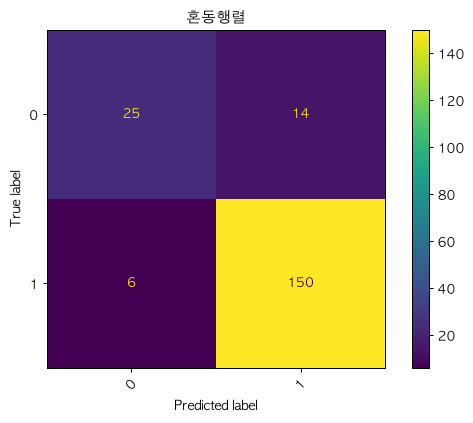

In [1]:
# 🤖 머신러닝 단계 — 그대로 실행해요
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split   # 학습용·시험용 나누기
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
df = pd.read_csv('https://baehwa-ai-2026.web.app/dataproject/csv/m03.csv')
X = df[['1학기 성적(0~20)', '2학기 성적(0~20)', '주당 공부 시간(1~4)', '과거 낙제 횟수', '결석 일수', '나이', '친구와 외출(1~5)', '자유 시간(1~5)']]                     # 넣을 열(특징)
y = df['통과(0/1)']                     # 맞힐 정답(범주)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)   # 70% 학습 · 30% 시험
model = DecisionTreeClassifier(max_depth=3, random_state=0)   # 결정트리(질문 3단계까지)
model.fit(X_train, y_train)          # 학습
pred = model.predict(X_test)         # 시험용으로 예측
print('시험 정확도', round(accuracy_score(y_test, pred), 3))   # 맞힌 비율
ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45)   # 혼동행렬: 무엇을 무엇으로 헷갈렸나
plt.title('혼동행렬'); plt.tight_layout(); plt.show()